# 4 · Buying independence

Designs with two EGIs and two mission computers, costed and quantified across the exposure
range. See [Lesson 4](../docs/lessons/04-buying-independence.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from cyberccf import plotting
from cyberccf.independence_baseline import MISSION_HOURS, navigation_model, unreliability

plotting.use_style()

64 designs


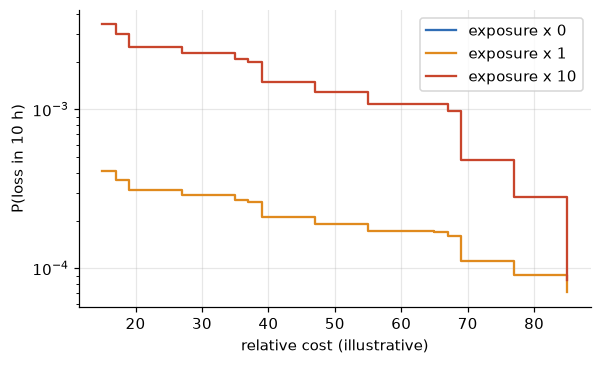

In [2]:
from cyberccf.architecture_diversity_tradeoff import (
    cost,
    enumerate_architectures,
    pareto_front,
    unreliability_at_scale,
)

archs = list(enumerate_architectures((2,), (2,)))
models = {a: a.model() for a in archs}
fig, ax = plt.subplots(figsize=(6, 3.5))
for s, color in zip((0.0, 1.0, 10.0), plotting.SERIES_COLORS):
    pts = [(cost(a), unreliability_at_scale(models[a], MISSION_HOURS, s), a) for a in archs]
    front = pareto_front(pts)
    ax.step([p[0] for p in front], [p[1] for p in front], where="post", color=color, label=f"exposure x {s:g}")
ax.set_yscale("log")
ax.set_xlabel("relative cost (illustrative)")
ax.set_ylabel("P(loss in 10 h)")
ax.legend();
print(len(archs), "designs")